## **TRANSFORMAÇÕES**

### **Aplicação de funções em colunas**

Uma indústria registra a temperatura dos equipamentos em graus Celsius (°C).

Entretanto, determinado relatório precisa apresentar essas temperaturas em Fahrenheit (°F).

Nosso objetivo é criar uma nova coluna com os valores convertidos, mantendo os dados originais.

In [ ]:
import pandas as pd

In [4]:
df_industria = pd.read_excel("df_industria.xlsx")

df_industria.head()

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,1014,2026-09-03,NaN,Noite,386.0,2,85.2,7.58,72.5,137.46
1,1040,2026-09-08,M-03,Noite,349.0,58,90.2,7.97,74.8,96.69
2,1031,2026-09-07,M-02,Manhã,365.0,3,70.0,5.27,68.0,106.69
3,1046,2026-09-10,M-04,Noite,264.0,6,79.6,5.26,51.0,126.49
4,1018,2026-09-04,M-01,Noite,373.0,5,89.7,6.69,75.2,780.00


In [5]:
df_industria.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   lote_id              50 non-null     int64         
 1   data_producao        50 non-null     datetime64[ns]
 2   maquina              49 non-null     object        
 3   turno                49 non-null     object        
 4   pecas_produzidas     49 non-null     float64       
 5   pecas_defeituosas    50 non-null     int64         
 6   temperatura_c        46 non-null     float64       
 7   pressao_bar          48 non-null     float64       
 8   tempo_ciclo_seg      50 non-null     float64       
 9   consumo_energia_kwh  49 non-null     float64       
dtypes: datetime64[ns](1), float64(5), int64(2), object(2)
memory usage: 4.0+ KB


In [6]:
# Função para converter Celsius em Fahrenheit
def converter_temperatura(celsius):
    return (celsius * 1.8) + 32

# Aplicando a função à coluna
df_industria["temperatura_f"] = df_industria["temperatura_c"].apply(converter_temperatura)

# Visualizando o resultado
display(df_industria[["temperatura_c", "temperatura_f"]].head(10))

,temperatura_c,temperatura_f
0,85.2,185.36
1,90.2,194.36
2,70.0,158.00
3,79.6,175.28
4,89.7,193.46
5,NaN,NaN
6,78.4,173.12
7,85.3,185.54
8,69.0,156.20
9,NaN,NaN


In [7]:
# Utilizando apply() com funções lambda

# Definindo a tarifa de energia
tarifa = 0.85

# Calculando o custo da energia
df_industria["custo_energia"] = df_industria["consumo_energia_kwh"].apply(lambda consumo: consumo * tarifa)

#df_industria["custo_energia"] = df_industria["consumo_energia_kwh"] * tarifa

# Visualizando o resultado
display(df_industria[["consumo_energia_kwh", "custo_energia"]].head(10).round(2))

,consumo_energia_kwh,custo_energia
0,137.46,116.84
1,96.69,82.19
2,106.69,90.69
3,126.49,107.52
4,780.00,663.00
5,129.07,109.71
6,160.33,136.28
7,154.68,131.48
8,119.83,101.86
9,129.07,109.71


In [11]:
# criando colunas mês e ano com função lambda
df_industria["ano"] = df_industria["data_producao"].apply(lambda data: str(data)[0:4])

df_industria["mes"] = df_industria["data_producao"].apply(lambda data: str(data)[5:7])

df_industria.head()

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh,temperatura_f,custo_energia,ano,mes
0,1014,2026-09-03,NaN,Noite,386.0,2,85.2,7.58,72.5,137.46,185.36,116.8410,2026,09
1,1040,2026-09-08,M-03,Noite,349.0,58,90.2,7.97,74.8,96.69,194.36,82.1865,2026,09
2,1031,2026-09-07,M-02,Manhã,365.0,3,70.0,5.27,68.0,106.69,158.00,90.6865,2026,09
3,1046,2026-09-10,M-04,Noite,264.0,6,79.6,5.26,51.0,126.49,175.28,107.5165,2026,09
4,1018,2026-09-04,M-01,Noite,373.0,5,89.7,6.69,75.2,780.00,193.46,663.0000,2026,09


Uma indústria deseja gerar uma descrição automática das condições operacionais de cada registro, combinando temperatura e pressão.

In [12]:
# Criando uma função que utiliza duas colunas
def resumo_operacional(linha):
    temperatura = linha["temperatura_c"]
    pressao = linha["pressao_bar"]

    return f"Temperatura: {temperatura} °C | Pressão: {pressao} bar"


# Aplicando a função em cada linha
df_industria["resumo"] = df_industria.apply(resumo_operacional, axis=1)

# Visualizando o resultado
display(df_industria[["temperatura_c", "pressao_bar", "resumo"]].head(10))

,temperatura_c,pressao_bar,resumo
0,85.2,7.58,Temperatura: 85.2 °C | Pressão: 7.58 bar
1,90.2,7.97,Temperatura: 90.2 °C | Pressão: 7.97 bar
2,70.0,5.27,Temperatura: 70.0 °C | Pressão: 5.27 bar
3,79.6,5.26,Temperatura: 79.6 °C | Pressão: 5.26 bar
4,89.7,6.69,Temperatura: 89.7 °C | Pressão: 6.69 bar
5,NaN,6.64,Temperatura: nan °C | Pressão: 6.64 bar
6,78.4,6.22,Temperatura: 78.4 °C | Pressão: 6.22 bar
7,85.3,23.50,Temperatura: 85.3 °C | Pressão: 23.5 bar
8,69.0,5.16,Temperatura: 69.0 °C | Pressão: 5.16 bar
9,NaN,6.64,Temperatura: nan °C | Pressão: 6.64 bar


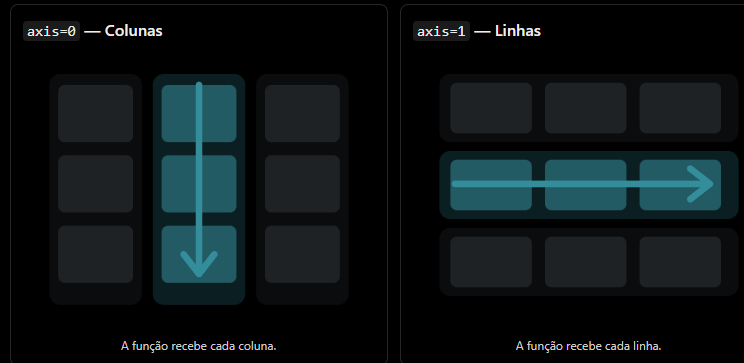

In [13]:
# Importando funções de arquivos .py

# Importando a função
from funcoes import limpar_turno

# preenchendo valores nulos
df_industria["turno"] = df_industria["turno"].fillna("NI") # Não Informado

# Aplicando à coluna turno
df_industria["turno_limpo"] = df_industria["turno"].apply(limpar_turno)

# Comparando os resultados
display(df_industria[["turno", "turno_limpo"]].head(10))

,turno,turno_limpo
0,Noite,NOITE
1,Noite,NOITE
2,Manhã,MANHA
3,Noite,NOITE
4,Noite,NOITE
5,Manhã,MANHA
6,Tarde,TARDE
7,Manhã,MANHA
8,Tarde,TARDE
9,Manhã,MANHA


### **Transformações Condicionais**

In [15]:
# Criando uma função condicional

# Função para classificar temperaturas
def classificar_temperatura(temperatura):

    if temperatura > 80:
        return "ALERTA"
    else:
        return "NORMAL"

In [16]:
# Criando uma nova coluna
df_industria["status_temperatura"] = df_industria["temperatura_c"].apply(classificar_temperatura)

# Visualizando o resultado
display(df_industria[["temperatura_c", "status_temperatura"]].head(10))

,temperatura_c,status_temperatura
0,85.2,ALERTA
1,90.2,ALERTA
2,70.0,NORMAL
3,79.6,NORMAL
4,89.7,ALERTA
5,NaN,NORMAL
6,78.4,NORMAL
7,85.3,ALERTA
8,69.0,NORMAL
9,NaN,NORMAL


In [17]:
# Transformações condicionais com np.where()

import numpy as np

# Classificando as temperaturas
df_industria["status_temperatura"] = np.where(df_industria["temperatura_c"] > 80,"ALERTA", "NORMAL")

# Visualizando o resultado
display(df_industria[["temperatura_c", "status_temperatura"]].head(10))

,temperatura_c,status_temperatura
0,85.2,ALERTA
1,90.2,ALERTA
2,70.0,NORMAL
3,79.6,NORMAL
4,89.7,ALERTA
5,NaN,NORMAL
6,78.4,NORMAL
7,85.3,ALERTA
8,69.0,NORMAL
9,NaN,NORMAL


Atenção aos valores ausentes

Se temperatura_c contiver NaN, a comparação > 80 será falsa para valores NaN numéricos usuais,

e o código poderá classificá-los incorretamente como "NORMAL".

In [ ]:
# Transformações condicionais com df.loc[]

# Criando uma coluna com classificação inicial
df_industria["status_consumo"] = "NORMAL"

# Alterando apenas os registros com consumo elevado
df_industria.loc[
    df_industria["consumo_energia_kwh"] > 200, "status_consumo"] = "ELEVADO"

# Visualizando o resultado
display(df_industria[["consumo_energia_kwh", "status_consumo"]].head(10))

### **Concatenação de Datasets**

In [18]:
# Criando os DataFrames

# Produção de janeiro
df_janeiro = pd.DataFrame({
    "equipamento": ["Máquina A", "Máquina B", "Máquina C"],
    "mes": ["Janeiro", "Janeiro", "Janeiro"],
    "producao": [1200, 1500, 1800]
})

# Produção de fevereiro
df_fevereiro = pd.DataFrame({
    "equipamento": ["Máquina A", "Máquina B", "Máquina C"],
    "mes": ["Fevereiro", "Fevereiro", "Fevereiro"],
    "producao": [1400, 1600, 2000]
})

# Criando o DataFrame de março
df_marco = pd.DataFrame({
    "equipamento": ["Máquina A", "Máquina B", "Máquina C"],
    "mes": ["Março", "Março", "Março"],
    "producao": [1600, 1750, 2100],
    "defeitos": [5, 8, 3]
})

In [19]:
display(df_janeiro)

,equipamento,mes,producao
0,Máquina A,Janeiro,1200
1,Máquina B,Janeiro,1500
2,Máquina C,Janeiro,1800


In [20]:
display(df_fevereiro)

,equipamento,mes,producao
0,Máquina A,Fevereiro,1400
1,Máquina B,Fevereiro,1600
2,Máquina C,Fevereiro,2000


In [21]:
display(df_marco)

,equipamento,mes,producao,defeitos
0,Máquina A,Março,1600,5
1,Máquina B,Março,1750,8
2,Máquina C,Março,2100,3


In [24]:
# Concatenando os dois DataFrames
df_producao = pd.concat([df_janeiro, df_fevereiro], ignore_index=True)

# Visualizando o resultado
display(df_producao)

,equipamento,mes,producao
0,Máquina A,Janeiro,1200
1,Máquina B,Janeiro,1500
2,Máquina C,Janeiro,1800
3,Máquina A,Fevereiro,1400
4,Máquina B,Fevereiro,1600
5,Máquina C,Fevereiro,2000


In [25]:
# Concatenando os três meses
df_trimestre = pd.concat(
    [df_janeiro, df_fevereiro, df_marco],
    ignore_index=True
)

# Visualizando o resultado
display(df_trimestre)

,equipamento,mes,producao,defeitos
0,Máquina A,Janeiro,1200,NaN
1,Máquina B,Janeiro,1500,NaN
2,Máquina C,Janeiro,1800,NaN
3,Máquina A,Fevereiro,1400,NaN
4,Máquina B,Fevereiro,1600,NaN
5,Máquina C,Fevereiro,2000,NaN
6,Máquina A,Março,1600,5.0
7,Máquina B,Março,1750,8.0
8,Máquina C,Março,2100,3.0


In [27]:
# Concatenação horizontal com axis=1
# um pouco menos utilizado

# Concatenando os DataFrames lado a lado
df_completo = pd.concat([df_janeiro, df_fevereiro], axis=1)

# Visualizando o resultado
display(df_completo)

,equipamento,mes,producao,equipamento,mes,producao
0,Máquina A,Janeiro,1200,Máquina A,Fevereiro,1400
1,Máquina B,Janeiro,1500,Máquina B,Fevereiro,1600
2,Máquina C,Janeiro,1800,Máquina C,Fevereiro,2000


Concatenando múltiplos arquivos com glob()

In [28]:
# Criando uma pasta

import os

# Criando uma pasta para armazenar os arquivos
os.makedirs("dados_producao", exist_ok=True)

In [ ]:
# Salvando os três DataFrames
df_janeiro.to_excel("dados_producao/01_janeiro.xlsx", index=False)

df_fevereiro.to_excel("dados_producao/02_fevereiro.xlsx", index=False)

df_marco.to_excel("dados_producao/03_marco.xlsx", index=False)

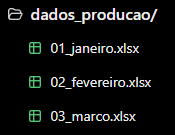

In [33]:
# Utilizando glob() e pd.concat()

from glob import glob

# Localizando todos os arquivos Excel da pasta
arquivos = sorted(glob("dados_producao/*.xlsx")) # organiza os caminhos em ordem

df_consolidado = pd.concat((pd.read_excel(cont) for cont in arquivos))

# Visualizando
display(df_consolidado)

,equipamento,mes,producao,defeitos
0,Máquina A,Janeiro,1200,NaN
1,Máquina B,Janeiro,1500,NaN
2,Máquina C,Janeiro,1800,NaN
0,Máquina A,Fevereiro,1400,NaN
1,Máquina B,Fevereiro,1600,NaN
2,Máquina C,Fevereiro,2000,NaN
0,Máquina A,Março,1600,5.0
1,Máquina B,Março,1750,8.0
2,Máquina C,Março,2100,3.0


In [32]:
df_consolidado['STATUS_META'] = (["meta_nao_batida" if producao < 1500 else "meta_batida"
                                   for producao in df_consolidado['producao']])

df_consolidado

,equipamento,mes,producao,defeitos,STATUS_META
0,Máquina A,Janeiro,1200,NaN,meta_nao_batida
1,Máquina B,Janeiro,1500,NaN,meta_batida
2,Máquina C,Janeiro,1800,NaN,meta_batida
0,Máquina A,Fevereiro,1400,NaN,meta_nao_batida
1,Máquina B,Fevereiro,1600,NaN,meta_batida
2,Máquina C,Fevereiro,2000,NaN,meta_batida
0,Máquina A,Março,1600,5.0,meta_batida
1,Máquina B,Março,1750,8.0,meta_batida
2,Máquina C,Março,2100,3.0,meta_batida
